### Import necessary packages

In [1]:
import muspan as ms
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import os
import json

### Define directories

In [ ]:
saved_domain_directory = r".\Template_Domains-with_Neighbourhoods"

saved_plots_directory = r".\Template_Domain-Plots"

if not os.path.exists(saved_plots_directory):
    os.makedirs(saved_plots_directory)

### Load saved domains

In [3]:
saved_domains = os.listdir(saved_domain_directory)

domains = []

for s_domain in saved_domains:
    domain = ms.io.load_domain(os.path.join(saved_domain_directory,s_domain))
    domains.append(domain)

MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_1.csv
Number of objects: 102476
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 10'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_2.csv
Number of objects: 415262
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 10'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_3.csv
Number of objects: 229276
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 10'] 
Networks: [] 
Di

### Function for plotting each subplot

In [4]:
def subjectively_better_subplots(nrows, ncols, margin= 0.5, header = 0.75, subheight = 8, subwidth= 8): ## now it is in cm, adjust margin, header, subheight, subwidth

    m = margin /2.54
    h = header /2.54

    a = subheight/2.54
    b = subwidth /2.54

    ## Here I calculate the figure size that you need for these parameters, as OP asked for. 

    width = ncols * (m + b+ m)
    height = nrows * (h +a +h)

    axarr = np.empty((nrows, ncols), dtype =object)
    
    #print(height, width)

    fig = plt.figure(figsize=(width, height))

    for i in range(nrows):
        for j in range(ncols):
            axarr[i,j] = fig.add_axes([(m+j*(2*m+b))/width,
                (height - (i+1)*(2*h+a)+h)/height,
                b/width,
                a/height])
            
    return fig, axarr

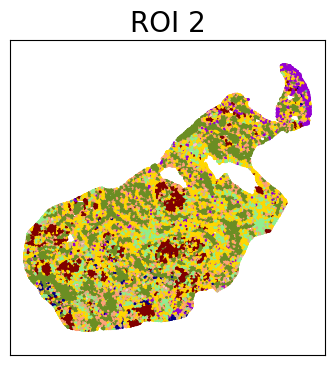

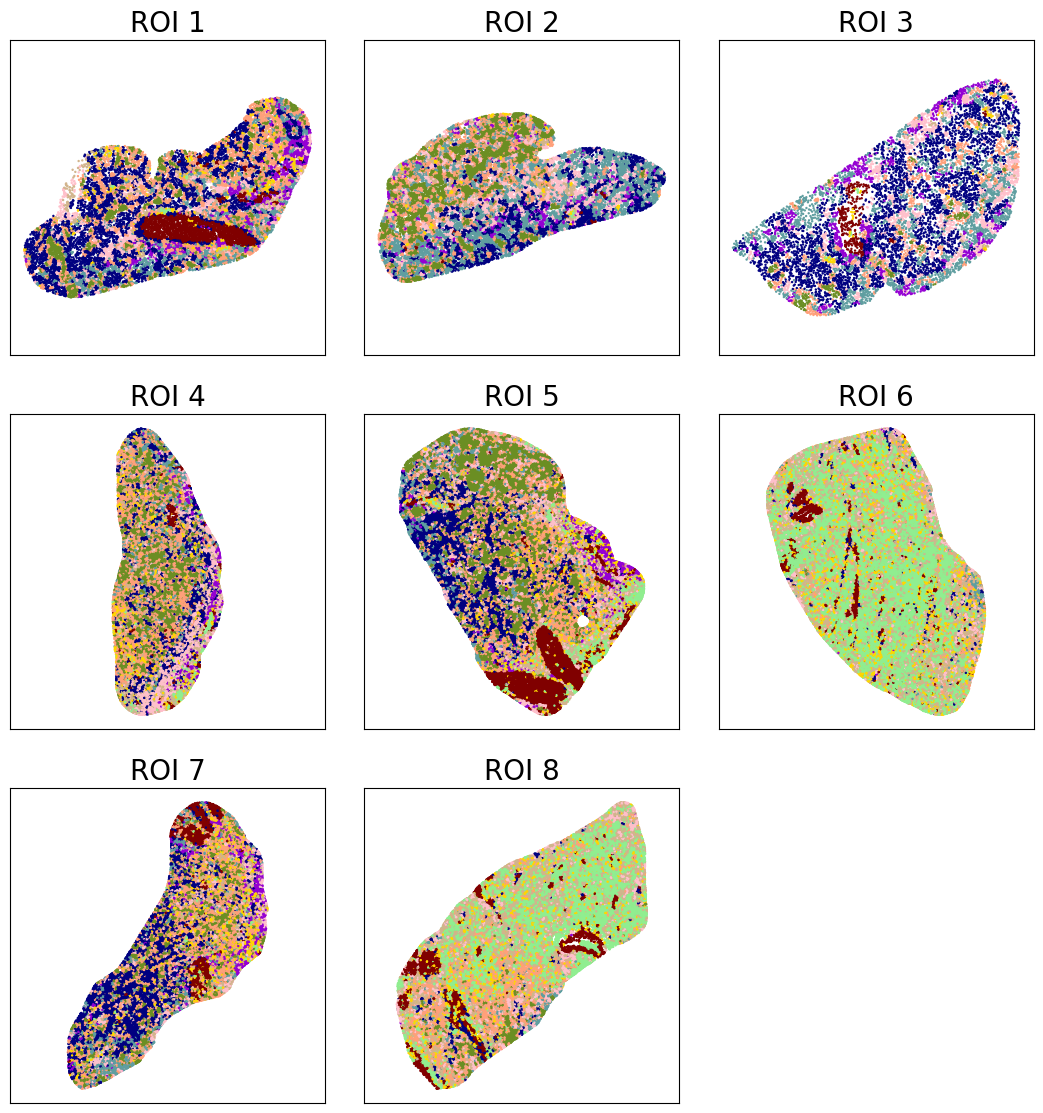

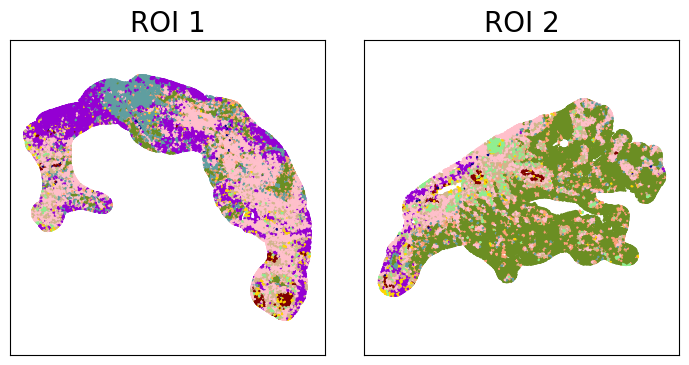

In [5]:
# Set font_sizes
font_title = {'family':'sans-serif', 'color':'black','size':20} #https://matplotlib.org/stable/users/explain/text/text_props.html#text-props

for domain in domains:
    ROIs = domain.labels["ROI"]["categories"]
    nROI = len(ROIs)

    if nROI <= 3:
        nrows = 1
        ncols = nROI
    else:
        nrows = (nROI+2)//3
        ncols = 3

    fig, axarr = subjectively_better_subplots(nrows=nrows, ncols=ncols)

    n = 0

    for i in range(nrows):
        for j in range(ncols):
            if n < nROI:
                cur_query = ms.query.query(domain, ('label', 'ROI'), 'is', ROIs[n])
                ms.visualise.visualise(domain, ax=axarr[i,j], objects_to_plot=cur_query, color_by='Neighbourhood ID - KNN 10', add_cbar=False, marker_size=0.5) # Make sure to change the color_by name to a label that exists in the domain

                axarr[i,j].set_title(ROIs[n], fontdict=font_title, loc="center")
                axarr[i,j].set_xticks([])
                axarr[i,j].set_yticks([])

                n += 1
            else:
                axarr[i,j].set_axis_off()

    # https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html
    plt.savefig(os.path.join(saved_plots_directory,str(domain.name))[:-4]+".png", transparent=None, dpi='figure', format='png',
        metadata=None, bbox_inches="tight", pad_inches=0.1,
        facecolor='auto', edgecolor='auto', backend=None)
                

### Plot colour bar separately

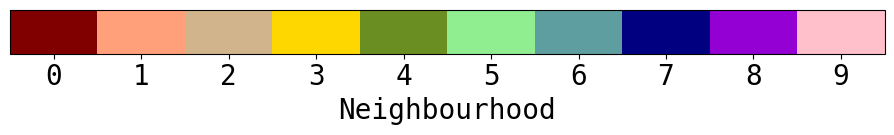

In [6]:
from matplotlib import colormaps 

fig, ax = plt.subplots(figsize=(10,8))
plt.rcParams['font.size'] = '20'
plt.rcParams['font.family'] = ['monospace'] #  {'cursive', 'fantasy', 'monospace', 'sans', 'sans serif', 'sans-serif', 'serif'}
# Make sure to change the color_by name to a label that exists in the domain
ms.visualise.visualise(domains[0], ax=ax, color_by="Neighbourhood ID - KNN 10", marker_size=1, add_cbar=True, cbar_kwargs={'location': 'bottom', #right, bottom
                                                                                                                           'orientation': 'horizontal', #vertical, horizontal
                                                                                                                           'label':'Neighbourhood'})

ax.set_visible(False)